# 02 — SST pattern decomposition

For each event, the July–June mean SST anomaly (relative to the 1979–2013
climatology) is split into the three lower boundary conditions of the AGCM runs:

* **FULL** — the anomaly, kept at full weight over 10.25°S–10.25°N and tapered
  linearly to zero at 13.98°S/N;
* **UNIFORM** — the cosine-weighted mean of FULL over 13.98°S–13.98°N (ocean points),
  applied as a constant over the same band;
* **PATTERN** — FULL − UNIFORM, which has zero tropical mean by construction.

FULL = UNIFORM + PATTERN holds at every grid point.

**Outputs:** `{year}_FULL.nc`, `{year}_UNIFORM.nc`, `{year}_PATTERN.nc` in
`cfg.DATA_AMIP_ELNINO_DIR` / `cfg.DATA_AMIP_LANINA_DIR`, and the column
`sst_mean_input` (the UNIFORM value, °C) in the analysis table.

In [1]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

## Which events to process

The event list comes from the analysis table seeded by `01`. Processing
one event first (2012) is a quick test of the whole notebook; switch to
`ALL_EVENTS` for the 23-event run.

In [2]:
analysis_df = pd.read_csv(cfg.ANALYSIS_CSV_PATH)
ALL_EVENTS = analysis_df[["Year", "Event"]].drop_duplicates().sort_values("Year").to_dict("records")

EVENTS_TO_PROCESS = [e for e in ALL_EVENTS if e["Year"] == 2012]
# EVENTS_TO_PROCESS = ALL_EVENTS   # <- full run, all 23 events
print(f"{len(ALL_EVENTS)} events available, processing {len(EVENTS_TO_PROCESS)} now")

23 events available, processing 1 now


## Step 1 — 1979–2013 climatology

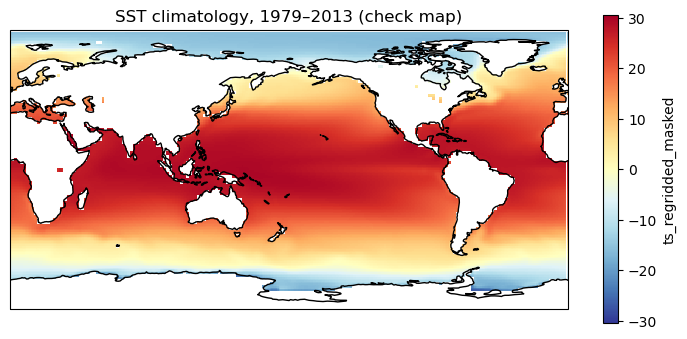

In [3]:
sst = xr.open_dataset(cfg.AMIP_TS_1DEG_MASKED_PATH)["ts_regridded_masked"] - 273.15
climatology = sst.sel(time=slice("1979-01", "2013-12")).groupby("time.month").mean("time").mean("month")


def show(field, title, vmin=-3, vmax=3, cmap="RdYlBu_r"):
    plt.figure(figsize=(9, 4))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    ax.coastlines()
    field.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, vmin=vmin, vmax=vmax)
    plt.title(title)
    plt.show()


show(climatology, "SST climatology, 1979–2013 (check map)", vmin=None, vmax=None)

## Step 2 — quick check: one event's raw anomaly, before tapering

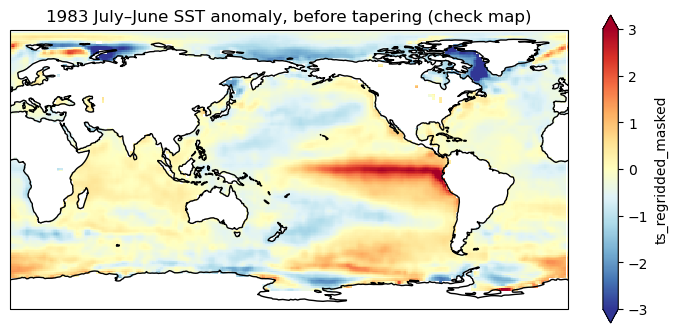

In [4]:
def event_anomaly(year):
    """July (year-1) to June (year) mean SST minus the climatology."""
    window_mean = sst.sel(time=slice(f"{year-1}-07", f"{year}-06")).mean("time")
    return window_mean - climatology


CHECK_EVENT_YEAR = 1983   # <- any event year from 01's table

show(event_anomaly(CHECK_EVENT_YEAR), f"{CHECK_EVENT_YEAR} July–June SST anomaly, before tapering (check map)")

## Step 3 — taper and decomposition

In [5]:
def taper_weight(lat):
    if -10.25 <= lat <= 10.25:
        return 1.0
    if 10.25 < lat <= 13.98:
        return (13.98 - lat) / (13.98 - 10.25)
    if -13.98 <= lat < -10.25:
        return (lat + 13.98) / (-10.25 + 13.98)
    return 0.0


taper = xr.DataArray([taper_weight(lat) for lat in sst.lat.values], coords=[sst.lat], dims=["lat"])
taper, _ = xr.broadcast(taper, sst.isel(time=0))
cos_weights = np.cos(np.deg2rad(sst.lat))


def decompose_event(year):
    """FULL, UNIFORM and PATTERN fields for one event, exactly as written to disk."""
    full = (event_anomaly(year) * taper).where(taper > 0)
    uniform_val = full.weighted(cos_weights).mean(["lat", "lon"]).item()
    uniform = xr.full_like(full, uniform_val).where(taper > 0)
    pattern = full - uniform
    return dict(full=full, uniform=uniform, pattern=pattern, uniform_val=uniform_val)

## Step 4 — quick check: the decomposition that will be saved

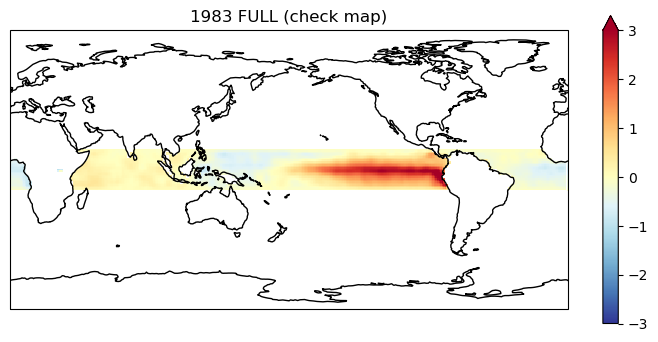

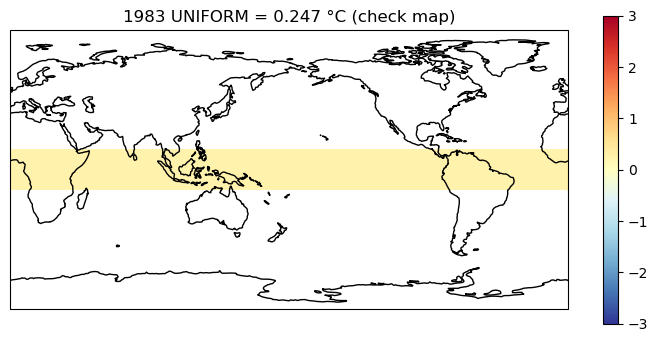

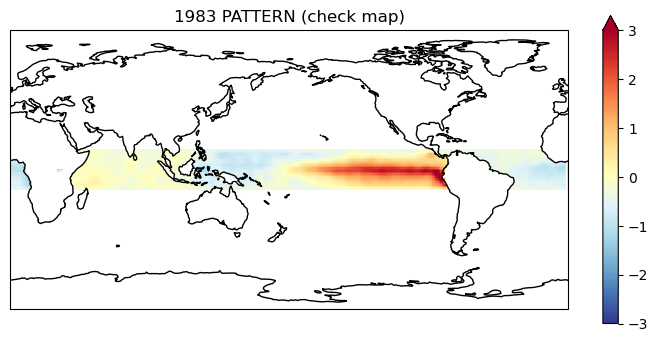

PATTERN tropical mean = -5.44e-15 °C (should be ~0); max |FULL - UNIFORM - PATTERN| = 0.0e+00


In [6]:
check = decompose_event(CHECK_EVENT_YEAR)
show(check["full"], f"{CHECK_EVENT_YEAR} FULL (check map)")
show(check["uniform"], f"{CHECK_EVENT_YEAR} UNIFORM = {check['uniform_val']:.3f} °C (check map)")
show(check["pattern"], f"{CHECK_EVENT_YEAR} PATTERN (check map)")

pattern_mean = check["pattern"].weighted(cos_weights).mean(["lat", "lon"]).item()
residual = float(abs(check["full"] - check["uniform"] - check["pattern"]).max())
print(f"PATTERN tropical mean = {pattern_mean:.2e} °C (should be ~0); max |FULL - UNIFORM - PATTERN| = {residual:.1e}")

## Step 5 — process and save every event in `EVENTS_TO_PROCESS`

In [7]:
def event_folder(event):
    return cfg.DATA_AMIP_ELNINO_DIR if event == "El Niño" else cfg.DATA_AMIP_LANINA_DIR


sst_mean_input = {}   # Year -> UNIFORM value (°C)

for e in EVENTS_TO_PROCESS:
    year, event = e["Year"], e["Event"]
    out_dir = event_folder(event)
    os.makedirs(out_dir, exist_ok=True)

    fields = decompose_event(year)
    sst_mean_input[year] = fields["uniform_val"]

    xr.Dataset({"sst_anomaly_tapered": fields["full"]}).to_netcdf(os.path.join(out_dir, f"{year}_FULL.nc"))
    xr.Dataset({"uniform_warming": fields["uniform"]}).to_netcdf(os.path.join(out_dir, f"{year}_UNIFORM.nc"))
    xr.Dataset({"sst_residual": fields["pattern"]}).to_netcdf(os.path.join(out_dir, f"{year}_PATTERN.nc"))
    print(f"saved FULL/UNIFORM/PATTERN for {year} {event} -> {out_dir}")

saved FULL/UNIFORM/PATTERN for 2012 La Niña -> /work/mh1421/m301201/data/data-amip/lanina


## Step 6 — store the UNIFORM value in the analysis table

In [8]:
existing = pd.read_csv(cfg.ANALYSIS_CSV_PATH)
if "sst_mean_input" not in existing.columns:
    existing["sst_mean_input"] = np.nan
for year, val in sst_mean_input.items():
    existing.loc[existing["Year"] == year, "sst_mean_input"] = val
existing.to_csv(cfg.ANALYSIS_CSV_PATH, index=False)
print(f"updated sst_mean_input for {len(sst_mean_input)} year(s)")

updated sst_mean_input for 1 year(s)


## Appendix — how the AGCM experiments were run (documentation, not executed)

The three fields above are regridded to the ECHAM6.3 T63 grid, added to the
climatological SST, and used as the lower boundary condition of three runs
per event (24 model years each, perturbation repeated every year):

```bash
cd /work/mh1421/m301201/0_model_requirements
python ./make_boundary_regrid.py

cd /work/mh1421/m301201/model2/mpiesm-landveg/util/running/tools
./Create_TASKS.frm mpiesm-as --id <EXPERIMENT_ID>
sbatch <EXPERIMENT_ID>.run
```

Each experiment's yearly output is then merged with `03_merge_model_output.ipynb`.